# 06 - Política de crédito por faixas de risco
Cortes sobre a probabilidade: aprovar (< 0,10), aprovar com ajuste (0,10-0,25), rejeitar (>= 0,25). Cortes escolhidos na validação e só depois conferidos no teste out-of-time.

In [1]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
pd.set_option('display.width', 200, 'display.max_columns', 50)


VALIDAÇÃO (onde os cortes são escolhidos)
    corte  aprovacao  inad_aprovados
0    0.04      0.160           0.032
1    0.06      0.354           0.039
2    0.08      0.517           0.047
3    0.10      0.629           0.054
4    0.12      0.705           0.059
5    0.14      0.766           0.063
6    0.16      0.808           0.067
7    0.18      0.838           0.069
8    0.20      0.859           0.070
9    0.22      0.873           0.071
10   0.24      0.884           0.072
11   0.26      0.892           0.073
12   0.28      0.899           0.074
13   0.30      0.904           0.075
14   0.32      0.909           0.077
15   0.34      0.915           0.078
16   0.36      0.919           0.080
17   0.38      0.925           0.082
18   0.40      0.930           0.084


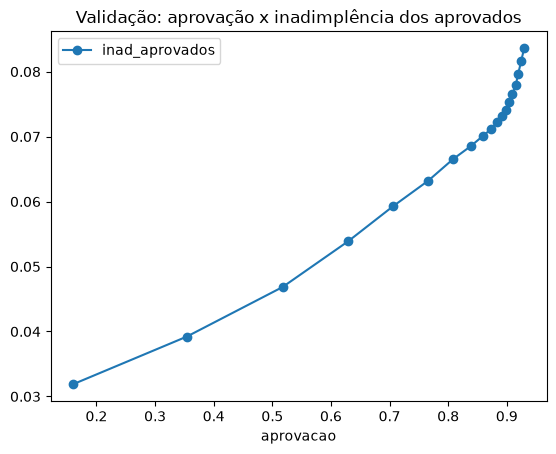

                    contratos  inadimplencia  pct_carteira
decisao                                                   
aprovar                 11190          0.054         0.629
aprovar com ajuste       4598          0.119         0.259
rejeitar                 1992          0.426         0.112


In [2]:
from src.train import *
from src.policy import *
m, cats, r, (X, y, tr, va, te, p) = rodar()
pv = m.predict_proba(X[va])[:, 1]
c = curva(y[va], pv); print('VALIDAÇÃO (onde os cortes são escolhidos)'); print(c.round(3).to_string())
c.plot(x='aprovacao', y='inad_aprovados', marker='o', title='Validação: aprovação x inadimplência dos aprovados'); plt.show()
print(resumo(y[va], pv).round(3))

In [3]:
print(resumo(y[te], p).round(3))
print('taxa base:', y[te].mean().round(3))
h = (X.loc[te, 'tem_historico'] == 1).values  # perfil de 96% da submissão
print('só com histórico, AUC', round(r['auc_com_historico'], 3)); print(resumo(y[te][h], p[h]).round(3))

                    contratos  inadimplencia  pct_carteira
decisao                                                   
aprovar                 16484          0.067         0.641
aprovar com ajuste       6977          0.161         0.271
rejeitar                 2268          0.409         0.088
taxa base: 0.123
só com histórico, AUC 0.733
                    contratos  inadimplencia  pct_carteira
decisao                                                   
aprovar                 15593          0.062         0.812
aprovar com ajuste       2034          0.121         0.106
rejeitar                 1582          0.446         0.082


In [4]:
sub = pd.read_csv('../submissao/submission_predictions.csv')
print(sub.decisao.value_counts(normalize=True).round(3))
print(sub.groupby('decisao').prob_inadimplencia.describe().round(3))

decisao
aprovar               0.664
rejeitar              0.189
aprovar com ajuste    0.147
Name: proportion, dtype: float64
                      count   mean    std    min    25%    50%    75%    max
decisao                                                                     
aprovar             33197.0  0.052  0.023  0.011  0.033  0.050  0.069  0.100
aprovar com ajuste   7352.0  0.147  0.042  0.100  0.111  0.133  0.175  0.250
rejeitar             9451.0  0.436  0.097  0.250  0.356  0.448  0.512  0.702


In [5]:
# o modelo final é retreinado com todas as safras: confere se a escala do score é a mesma do modelo validado
import joblib
from src.config import INTERIM, MODELS
from src.evaluate import psi
art = joblib.load(MODELS / 'lgbm.joblib'); S = aplicar_cat(pd.read_parquet(INTERIM / 'submission.parquet'), art['cats'])[art['cols']]
a, b = m.predict_proba(S)[:, 1], art['model'].predict_proba(S)[:, 1]
print('submissão: score médio modelo validado', a.mean().round(4), '| modelo final', b.mean().round(4), '| PSI', round(psi(a, b), 4), '| correlação', np.corrcoef(a, b)[0, 1].round(3))

submissão: score médio modelo validado 0.1456 | modelo final 0.1385 | PSI 0.0151 | correlação 0.972


In [6]:
# Ações sugeridas para 'aprovar com ajuste' (hipótese, não validada com dados): reduzir valor_credito, aumentar entrada, encurtar prazo.
# Extensão possível: simular com LGD/margem explícitas e sensibilidade (ver .claude/DECISIONS.md).